# Re-Annotation Analysis

This notebook is used to plot the figures for the Re-Annotation comparison (Sup. Fig. 6) that were created after running the respective preprocessing pipelines.

**NOTE:**
Before running this notebook, you need to run the re-annotation pipelines.

**INPUT:**

- 3x interactions.RData
- 3x anno_cells_cf_ctf_gf_sf.RData

**FIGURES:**

- 6a (Sup. Fig.)
- 6b/c/d (Sup. Fig.)
- 6e (Sup. Fig.)
- 6f (Sup. Fig.)
- 6g (Sup. Fig.)
- 6h (Sup. Fig.)

## Setup

In [1]:
library(dplyr)
library(ggplot2)
library(UpSetR)
library(igraph)
library(ggraph)

# Load an interactions.RData file and return the significant interactions as a data frame
load_significant_interactions <- function(rdata_path) {
  e <- new.env()
  suppressWarnings(load(rdata_path, envir = e))
  anno_interactions_df <- as.data.frame(e$interactions$anno_interactions)

  # Drop duplicated columns
  duplicate_columns <- names(anno_interactions_df)[duplicated(names(anno_interactions_df))]
  anno_interactions_df <- anno_interactions_df %>%
    select(-any_of(duplicate_columns))

  anno_interactions_df %>%
    filter(!is.na(p.value) & sign == TRUE)
}

# Per-gene frequency summary across ligands and receptors of significant interactions
compute_gene_summary <- function(interactions_df) {
  all_genes <- c(interactions_df$ligand_gene_name, interactions_df$receptor_gene_name)
  gene_counts <- as.data.frame(table(all_genes))
  names(gene_counts) <- c("all_genes", "Freq")

  gene_counts %>%
    mutate(Normalized_Freq_Total = Freq / nrow(interactions_df)) %>%
    arrange(desc(Freq))
}

library(circlize)
library(ComplexHeatmap)
library(grid)

# Load the fully filtered cell annotation exported by the filtering notebooks
load_filtered_anno_cells <- function(rdata_path) {
  e <- new.env()
  suppressWarnings(load(rdata_path, envir = e))
  e$anno_cells_cf_ctf_gf_sf
}

# Build the cell type x sample count table, with samples ordered by region
build_cell_count_matrix <- function(anno_cells) {
  anno_cells <- anno_cells %>%
    arrange(region)

  tab <- table(anno_cells$cell_subtype, anno_cells$sample_ID)
  df1 <- as.data.frame(matrix(tab, nrow = nrow(tab), dimnames = dimnames(tab)))

  # Reorder sample columns to region-sorted order
  df1[, unique(anno_cells$sample_ID)]
}

# Shared, fixed color scale so the heatmaps are comparable across annotations
col_fun <- colorRamp2(
  c(0, 10, 100, 1000, 6000),
  c("white", "#cfcfcf", "#bfbfbf", "salmon", "darkred")
)

plot_cell_count_heatmap <- function(anno_cells, title = NULL) {
  # Transpose so samples are rows and cell types are columns
  df1_transposed <- t(build_cell_count_matrix(anno_cells))

  h <- Heatmap(df1_transposed,
               cluster_rows = FALSE,
               col = col_fun,
               name = "nr cells",
               column_title = title,
               show_heatmap_legend = TRUE,
               column_names_gp = gpar(fontsize = 20),
               row_names_gp = gpar(fontsize = 20))

  # Draw inside a custom viewport (inside a function, Heatmap() does not auto-print)
  grid.newpage()
  pushViewport(viewport(width = 0.8, height = 0.8))
  draw(h, newpage = FALSE)
  popViewport()
}


Attache Paket: ‘dplyr’


Die folgenden Objekte sind maskiert von ‘package:stats’:

    filter, lag


Die folgenden Objekte sind maskiert von ‘package:base’:

    intersect, setdiff, setequal, union


Warning message:
“Paket ‘UpSetR’ wurde unter R Version 4.2.2 erstellt”
Warning message:
“Paket ‘igraph’ wurde unter R Version 4.2.2 erstellt”

Attache Paket: ‘igraph’


Die folgenden Objekte sind maskiert von ‘package:dplyr’:

    as_data_frame, groups, union


Die folgenden Objekte sind maskiert von ‘package:stats’:

    decompose, spectrum


Das folgende Objekt ist maskiert ‘package:base’:

    union


Warning message:
“Paket ‘ggraph’ wurde unter R Version 4.2.2 erstellt”
Warning message:
“Paket ‘circlize’ wurde unter R Version 4.2.2 erstellt”
circlize version 0.4.16
CRAN page: https://cran.r-project.org/package=circlize
Github page: https://github.com/jokergoo/circlize
Documentation: https://jokergoo.github.io/circlize_book/book/

If you use it in published research, please cite:
Gu, Z

## Load data

In [2]:
broad_interactions    <- load_significant_interactions("./broad/outs/interactions.RData")
general_interactions  <- load_significant_interactions("./general/outs/interactions.RData")
distinct_interactions <- load_significant_interactions("./distinct/outs/interactions.RData")

final_summary_broad    <- compute_gene_summary(broad_interactions)
final_summary_general  <- compute_gene_summary(general_interactions)
final_summary_distinct <- compute_gene_summary(distinct_interactions)

## Sup. Fig. 6a - Annotation hierarchy dendrogram

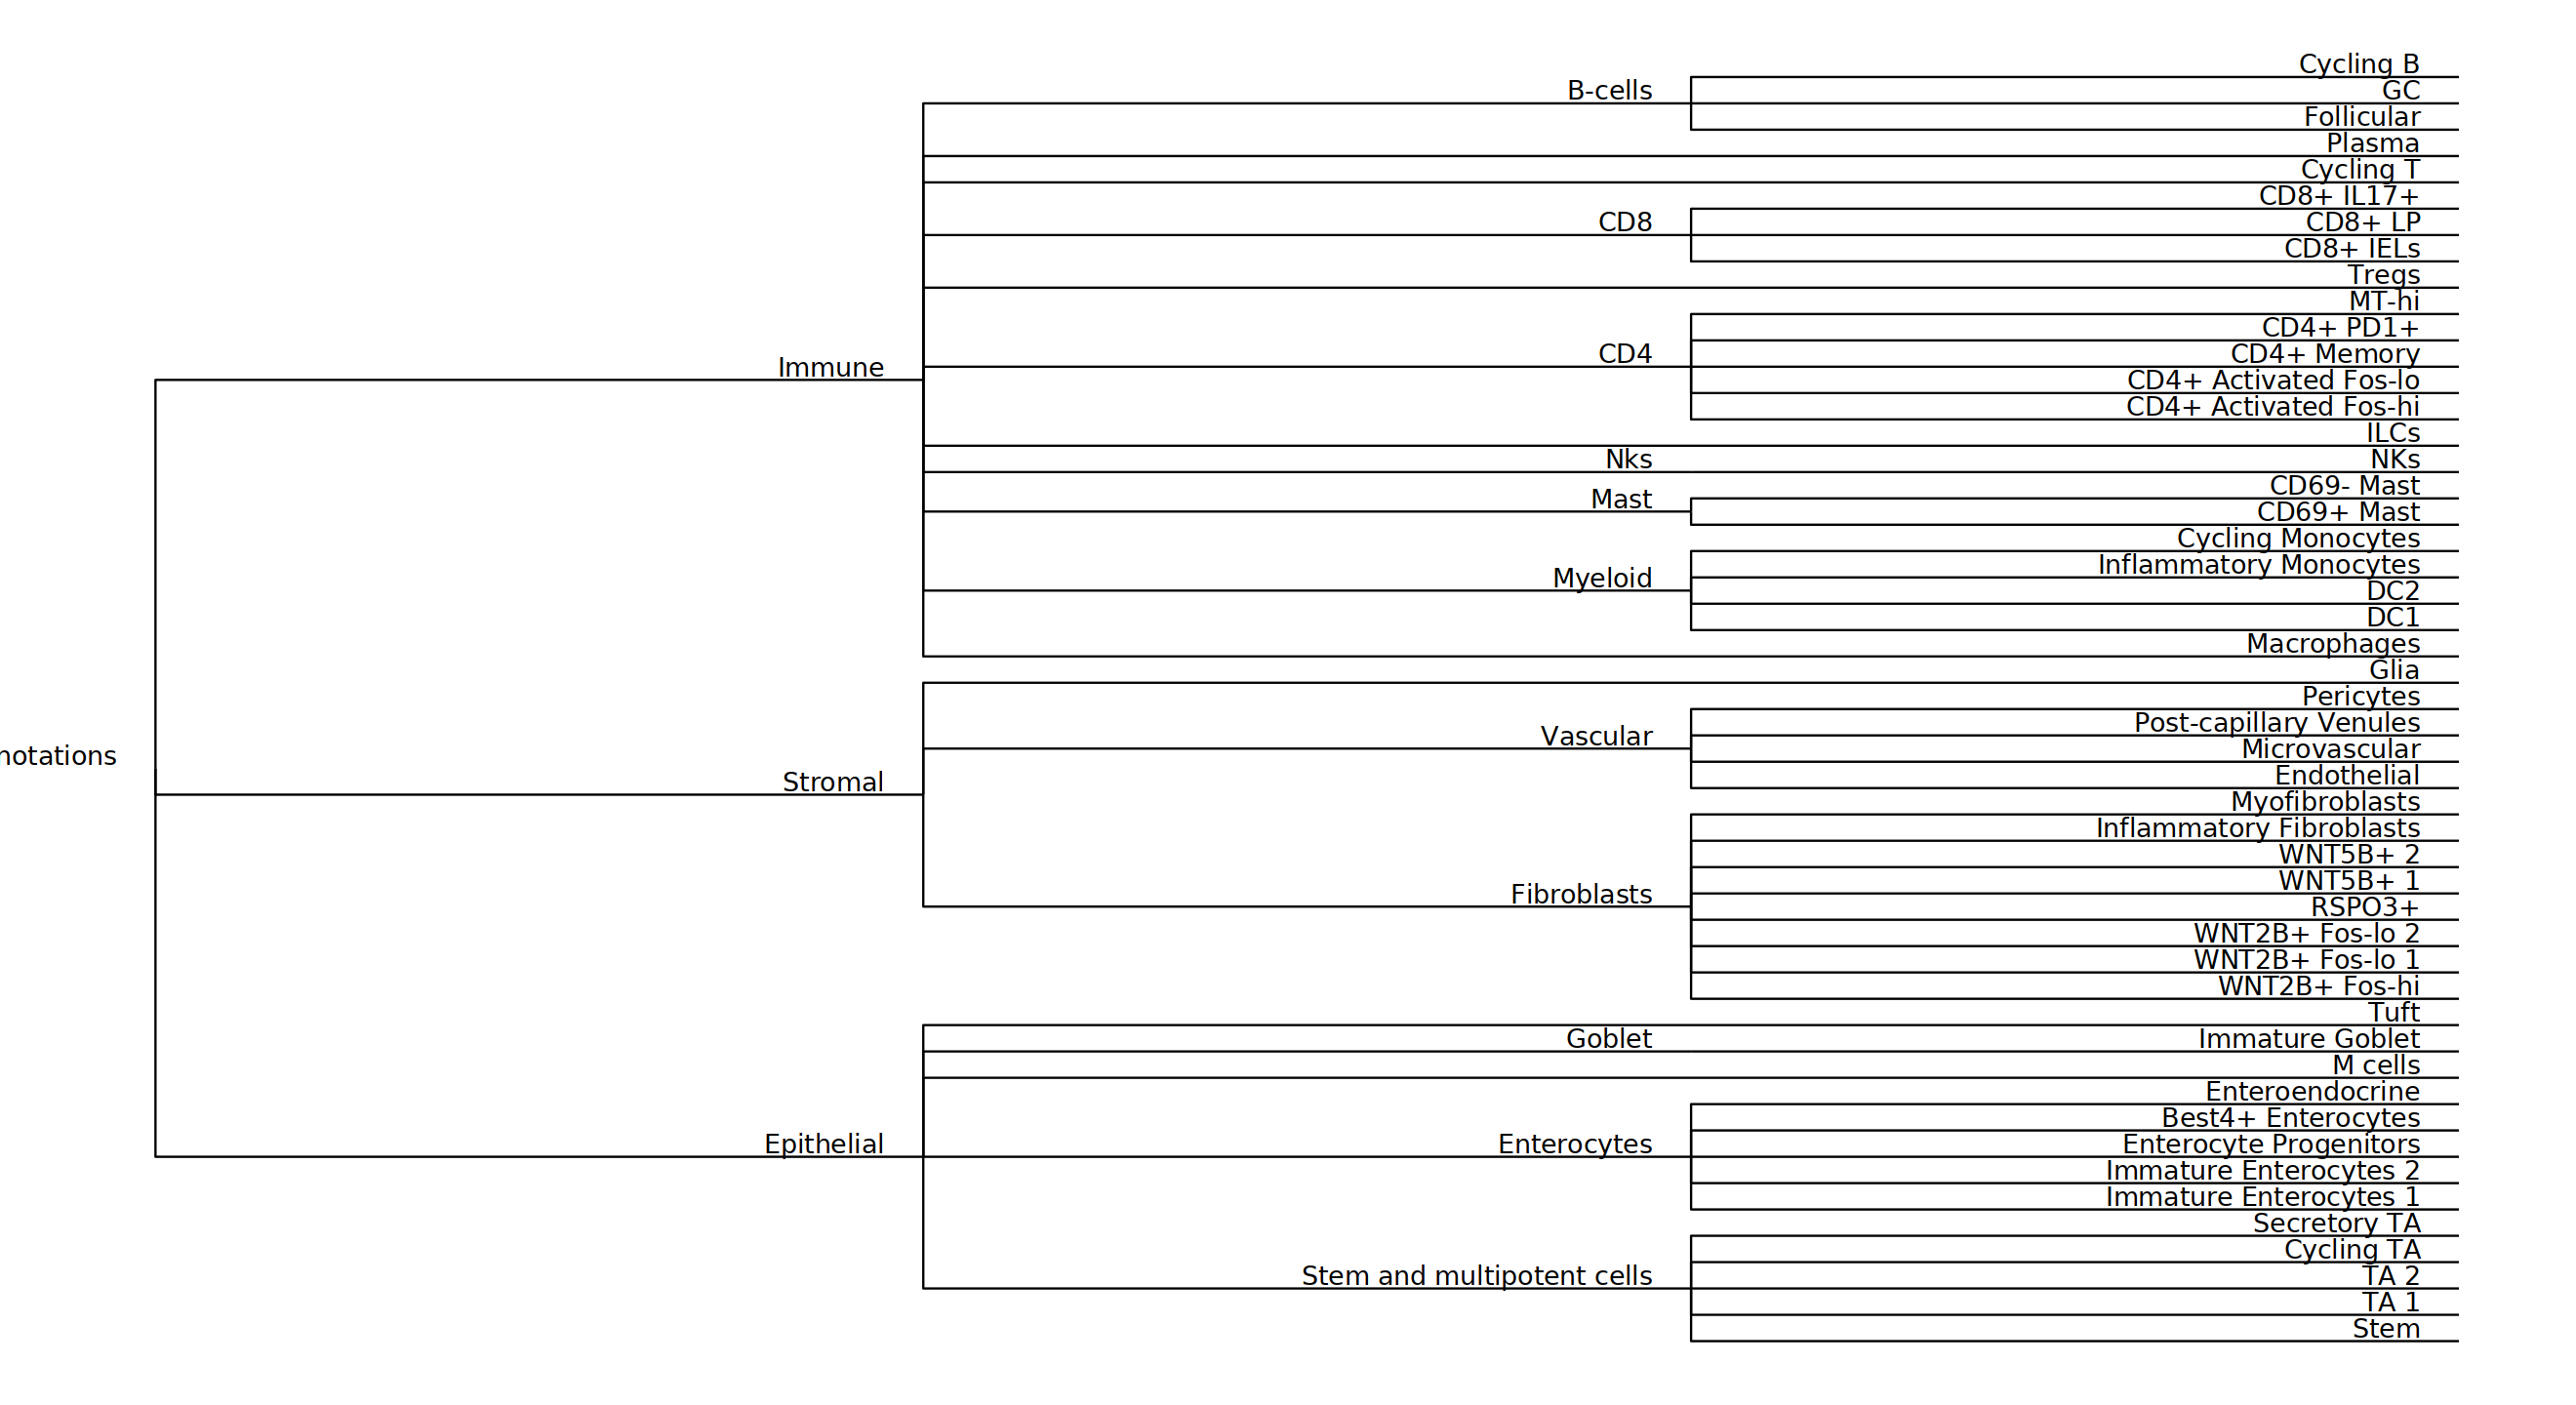

In [3]:
options(repr.plot.width=22, repr.plot.height=12)

#  Annotation hierarchy
csv_text <- "
cell_subtype_broad,cell_subtype_general,cell_subtype_distinct,cell_type_original
Epithelial,Stem and multipotent cells,Stem,Stem
Epithelial,Stem and multipotent cells,TA 1,TA 1
Epithelial,Stem and multipotent cells,TA 2,TA 2
Epithelial,Stem and multipotent cells,Cycling TA,Cycling TA
Epithelial,Enterocytes,Immature Enterocytes 1,Immature Enterocytes 1
Epithelial,Enterocytes,Immature Enterocytes 2,Immature Enterocytes 2
Epithelial,Enterocytes,Enterocyte Progenitors,Enterocyte Progenitors
Epithelial,Enterocytes,Enterocytes,Enterocytes
Epithelial,M cells,M cells,M cells
Epithelial,Enterocytes,Best4+ Enterocytes,Best4+ Enterocytes
Epithelial,Stem and multipotent cells,Secretory TA,Secretory TA
Epithelial,Goblet,Immature Goblet,Immature Goblet
Epithelial,Goblet,Goblet,Goblet
Epithelial,Tuft,Tuft,Tuft
Epithelial,Enterocytes,Enteroendocrine,Enteroendocrine
Stromal,Fibroblasts,WNT2B+ Fos-hi,WNT2B+ Fos-hi
Stromal,Fibroblasts,WNT2B+ Fos-lo 1,WNT2B+ Fos-lo 1
Stromal,Fibroblasts,WNT2B+ Fos-lo 2,WNT2B+ Fos-lo 2
Stromal,Fibroblasts,RSPO3+,RSPO3+
Stromal,Fibroblasts,WNT5B+ 1,WNT5B+ 1
Stromal,Fibroblasts,WNT5B+ 2,WNT5B+ 2
Stromal,Fibroblasts,Inflammatory Fibroblasts,Inflammatory Fibroblasts
Stromal,Fibroblasts,Myofibroblasts,Myofibroblasts
Stromal,Vascular,Endothelial,Endothelial
Stromal,Vascular,Microvascular,Microvascular
Stromal,Vascular,Post-capillary Venules,Post-capillary Venules
Stromal,Vascular,Pericytes,Pericytes
Stromal,Glia,Glia,Glia
Immune,Macrophages,Macrophages,Macrophages
Immune,Myeloid,DC1,DC1
Immune,Myeloid,DC2,DC2
Immune,Myeloid,Inflammatory Monocytes,Inflammatory Monocytes
Immune,Mast,CD69+ Mast,CD69+ Mast
Immune,Mast,CD69- Mast,CD69- Mast
Immune,Myeloid,Cycling Monocytes,Cycling Monocytes
Immune,Nks,NKs,NKs
Immune,ILCs,ILCs,ILCs
Immune,CD4,CD4+ Activated Fos-hi,CD4+ Activated Fos-hi
Immune,CD4,CD4+ Activated Fos-lo,CD4+ Activated Fos-lo
Immune,CD4,CD4+ Memory,CD4+ Memory
Immune,Tregs,Tregs,Tregs
Immune,CD4,CD4+ PD1+,CD4+ PD1+
Immune,CD8,CD8+ IELs,CD8+ IELs
Immune,CD8,CD8+ LP,CD8+ LP
Immune,CD8,CD8+ IL17+,CD8+ IL17+
Immune,CD4,MT-hi,MT-hi
Immune,Cycling T,Cycling T,Cycling T
Immune,Plasma,Plasma,Plasma
Immune,B-cells,Follicular,Follicular
Immune,B-cells,GC,GC
Immune,B-cells,Cycling B,Cycling B
"
data <- read.csv(textConnection(csv_text), header = TRUE, stringsAsFactors = FALSE)

# Create edge list for each level of the hierarchy
# Level 1: From 'root' to 'cell_subtype_broad'
edges_level1 <- data.frame(
  from = "annotations",
  to = unique(data$cell_subtype_broad)
)

# Level 2: From 'cell_subtype_broad' to 'cell_subtype_general'
edges_level2 <- unique(data[, c("cell_subtype_broad", "cell_subtype_general")])
colnames(edges_level2) <- c("from", "to")

# Level 3: From 'cell_subtype_general' to 'cell_subtype_distinct'
edges_level3 <- unique(data[, c("cell_subtype_general", "cell_subtype_distinct")])
colnames(edges_level3) <- c("from", "to")

# Combine all edges into a single data frame
edge_list <- rbind(edges_level1, edges_level2, edges_level3)

# Create the graph from the edge list
g <- graph_from_data_frame(edge_list, directed = TRUE)

ggraph(g, layout = 'dendrogram', circular = FALSE) + 
  geom_edge_elbow() +
  geom_node_text(aes(label = name), hjust = 1, nudge_x = 0.5, nudge_y = -0.05, size = 5.5) + 
  scale_y_reverse() + 
  coord_flip() + 
  theme_void()

## Sup. Fig. 6b/c/d - Cells per Sample and Cell Type

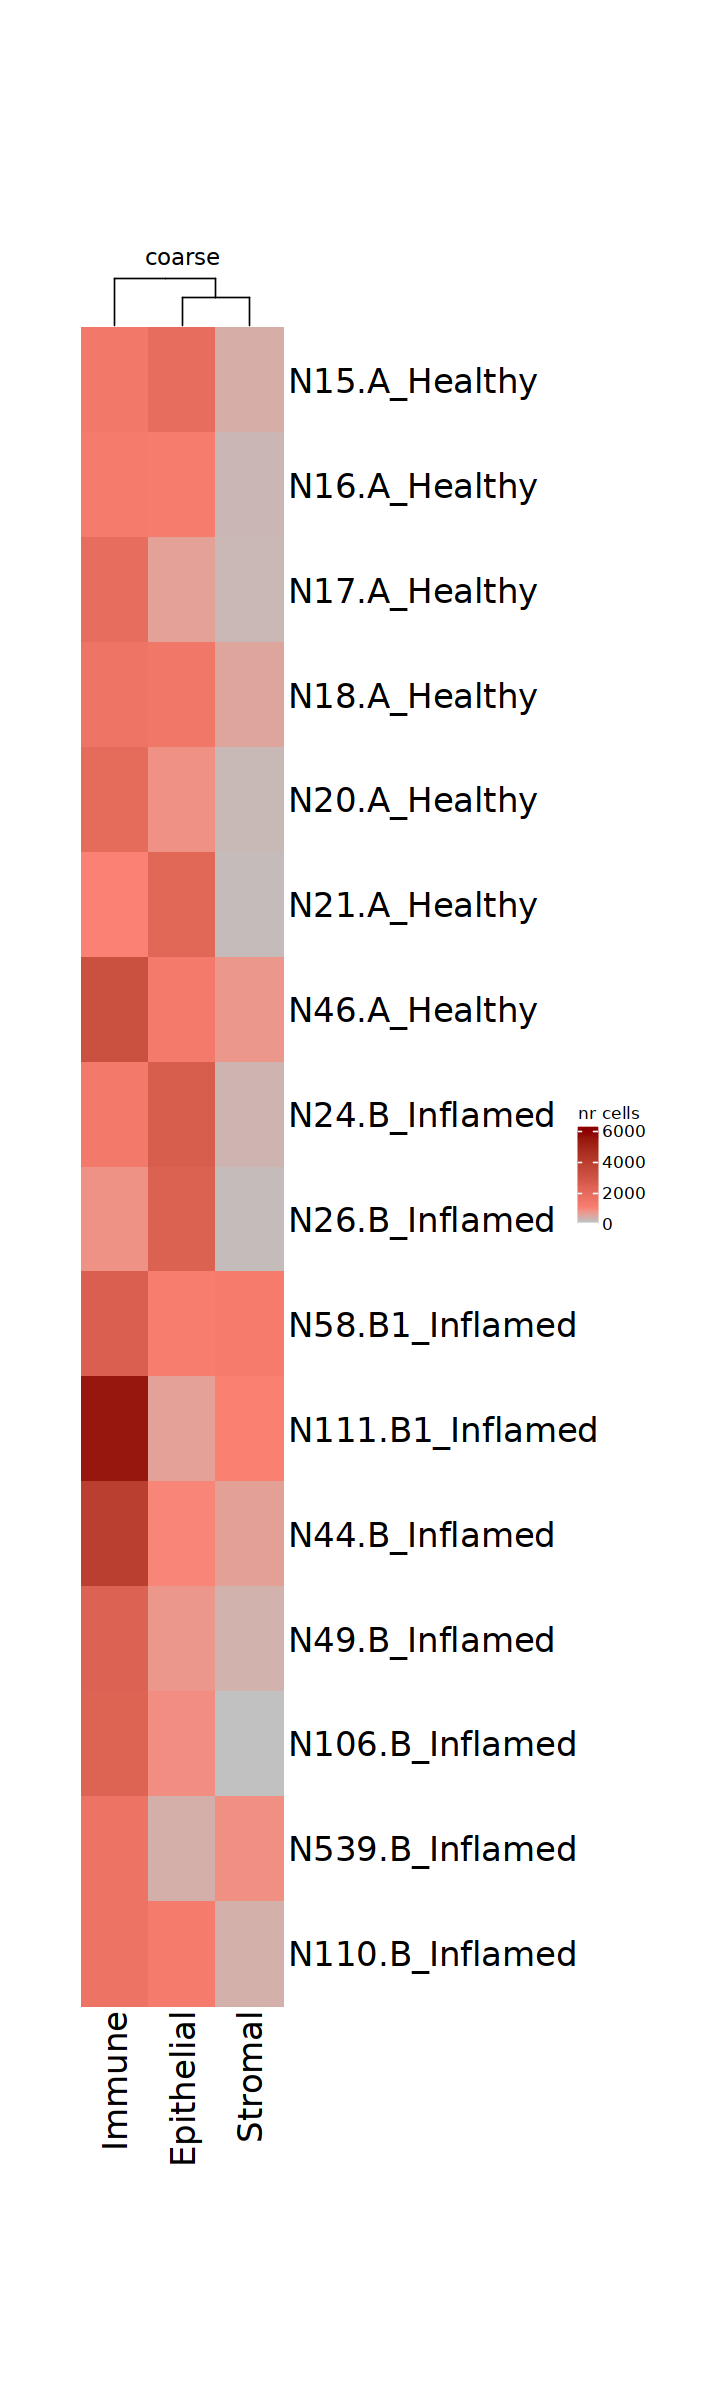

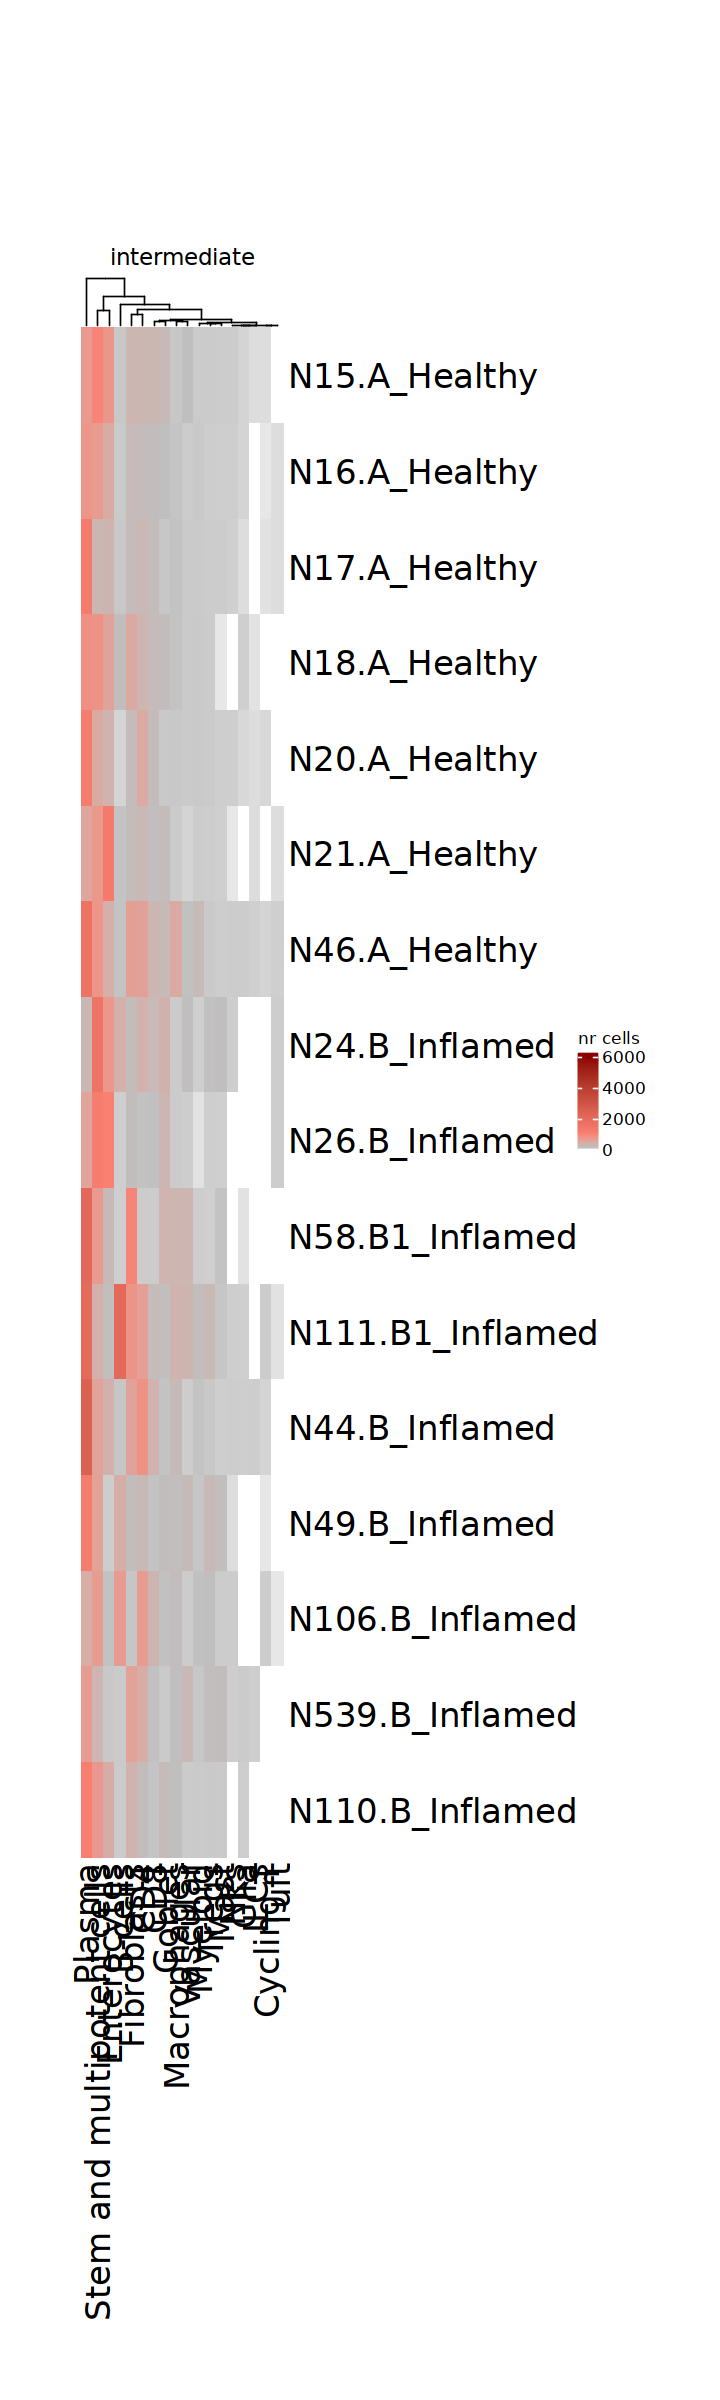

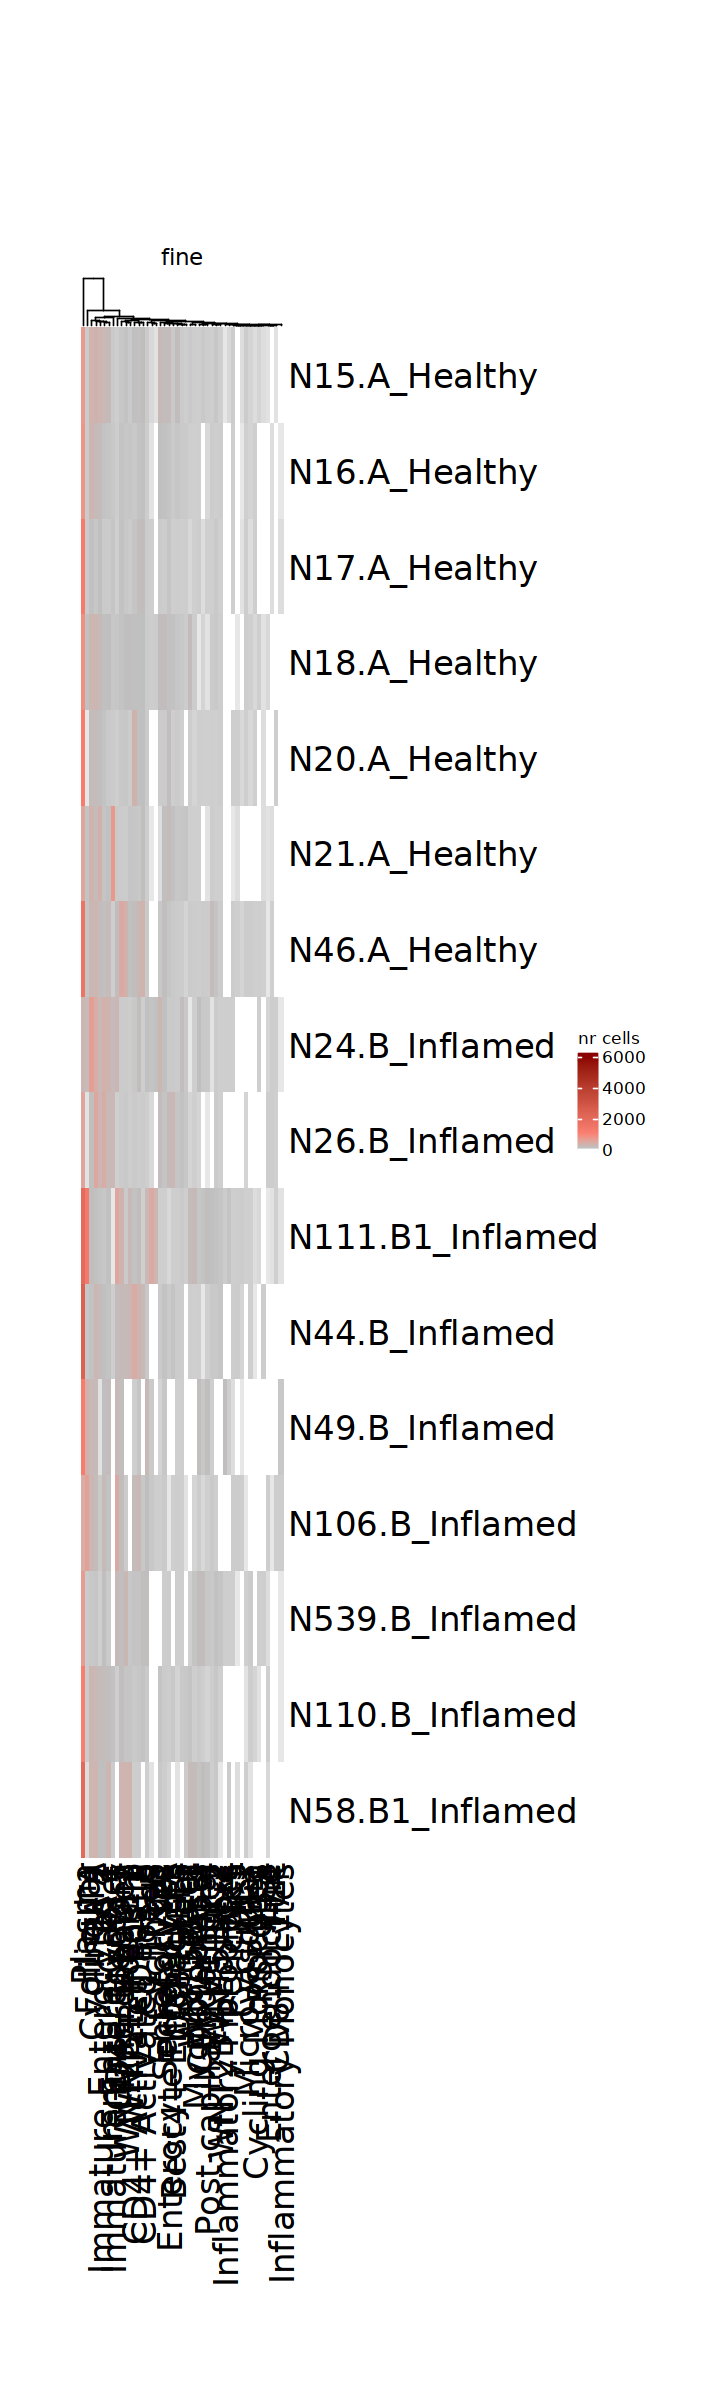

In [4]:
options(repr.plot.width=6, repr.plot.height=20)

annotation_dirs <- c(
  coarse       = "./broad",
  intermediate = "./general",
  fine         = "./distinct"
)

for (label in names(annotation_dirs)) {
  anno_cells <- load_filtered_anno_cells(
    paste0(annotation_dirs[[label]], "/outs/anno_cells_cf_ctf_gf_sf.RData")
  )
  plot_cell_count_heatmap(anno_cells, title = label)
}

## Sup. Fig. 6e - Number of Significant Interactions by Annotation Level

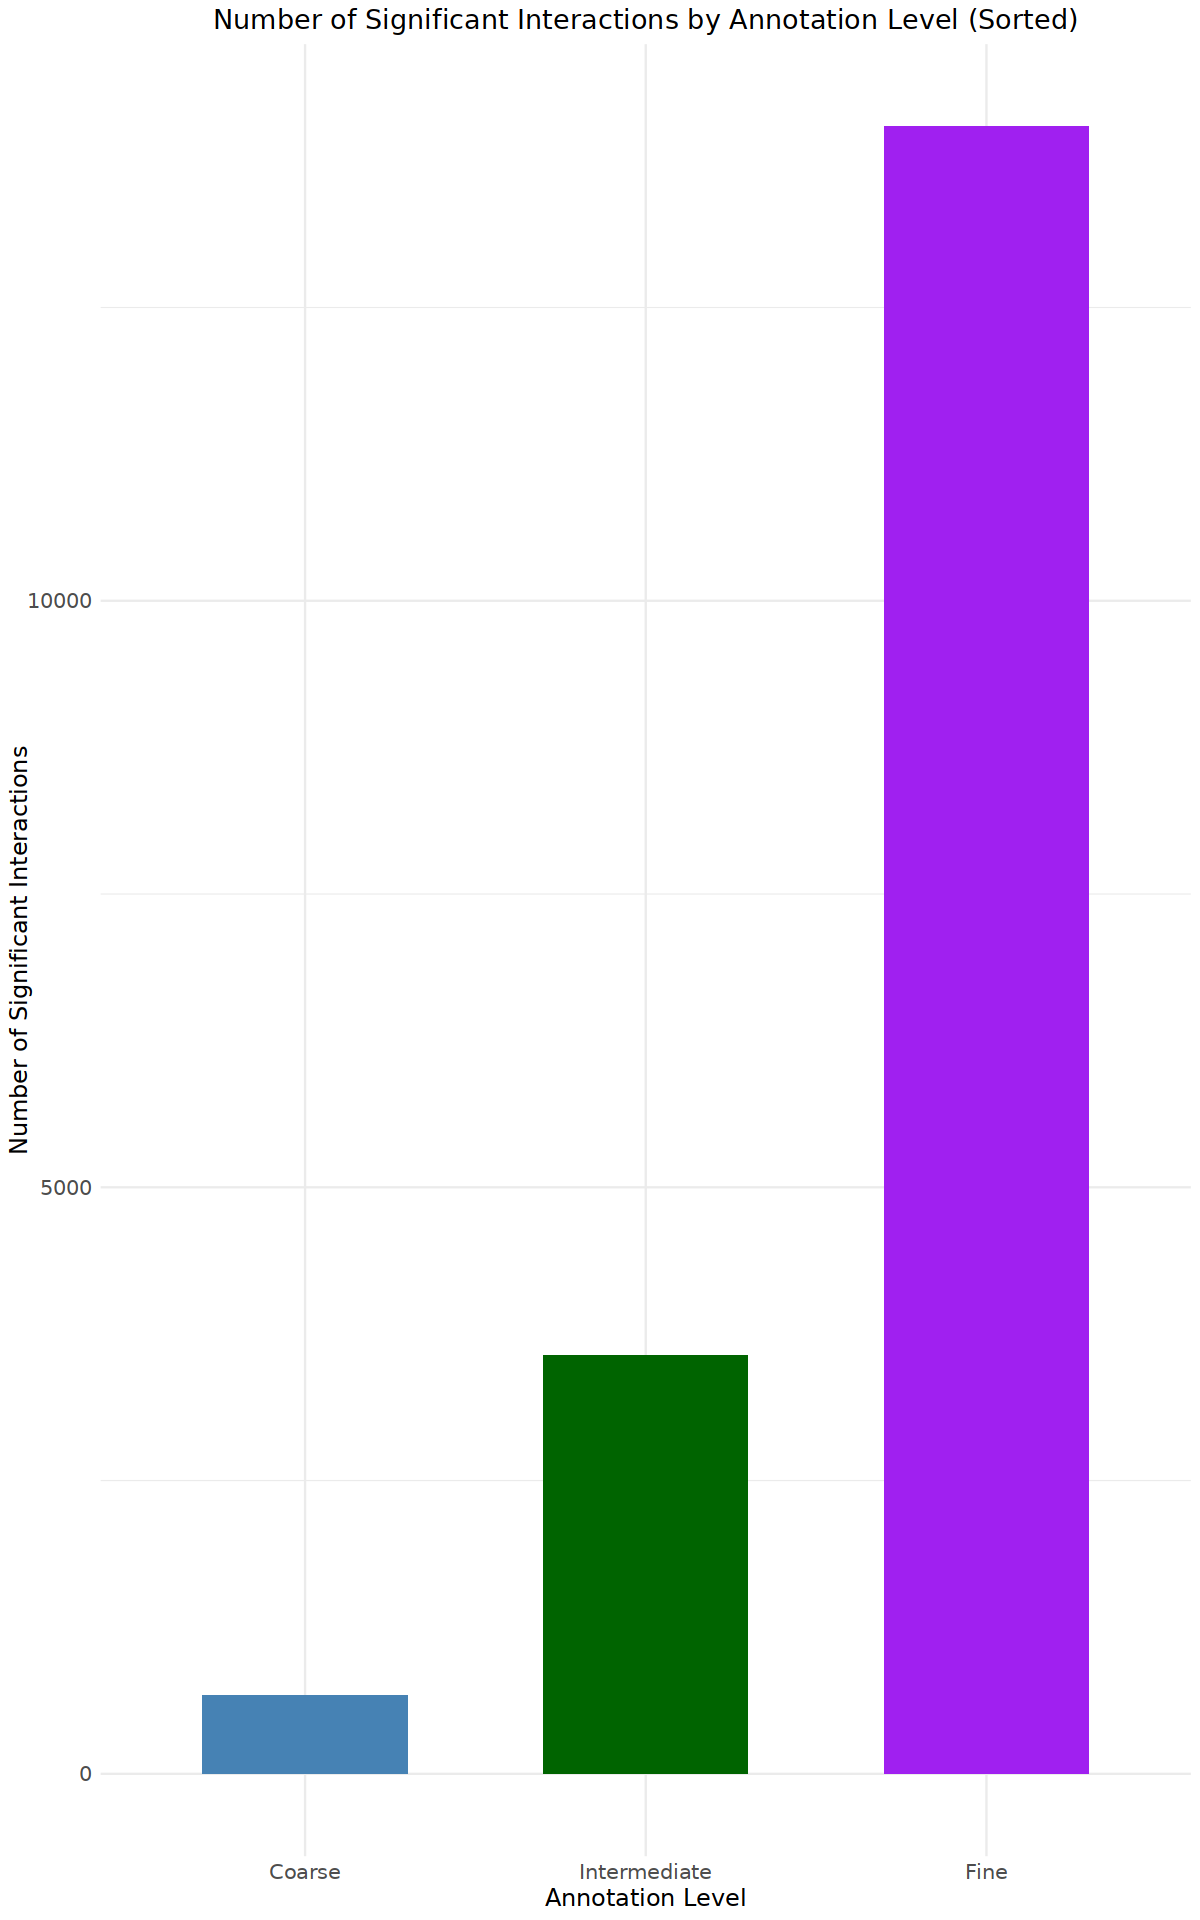

In [5]:
options(repr.plot.width=10, repr.plot.height=16)

# Count the number of significant interactions in each annotation
interaction_counts <- data.frame(
  Annotation_Level = c("Coarse", "Intermediate", "Fine"),
  Significant_Interactions = c(
    nrow(broad_interactions),
    nrow(general_interactions),
    nrow(distinct_interactions)
  )
)

# Reorder Annotation_Level based on Significant_Interactions (Ascending)
interaction_counts_sorted_asc <- interaction_counts %>%
  arrange(Significant_Interactions) %>%
  mutate(Annotation_Level = factor(Annotation_Level, levels = Annotation_Level))

# Bar Plot Sorted by Number of Interactions (Ascending)
ggplot(interaction_counts_sorted_asc, aes(x = Annotation_Level, y = Significant_Interactions, fill = Annotation_Level)) +
  geom_bar(stat = "identity", width = 0.6) +
  labs(
    title = "Number of Significant Interactions by Annotation Level (Sorted)",
    x = "Annotation Level",
    y = "Number of Significant Interactions"
  ) +
  theme_minimal() +
  theme(
    legend.position = "none",
    plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
    axis.title = element_text(size = 14),
    axis.text = element_text(size = 12)
  ) +
  scale_fill_manual(values = c("Coarse" = "steelblue", "Intermediate" = "darkgreen", "Fine" = "purple"))

## Sup. Fig. 6f - Number of Significant Interactions after Re-Annotation

In [6]:
# Remap fine/intermediate cell types to the coarse annotation
path_in <- "./../rdata"
remap_data <- read.csv(paste0(path_in, "/cell_remap.csv"), sep = ";")

remap_cell_types <- function(data, remap_data, from_col, to_col) {

  remap_dict <- setNames(remap_data[[to_col]], remap_data[[from_col]])

  data %>%
    mutate(
      sending_cell_type = ifelse(sending_cell_type %in% names(remap_dict), remap_dict[sending_cell_type], sending_cell_type),
      receiving_cell_type = ifelse(receiving_cell_type %in% names(remap_dict), remap_dict[receiving_cell_type], receiving_cell_type)
    )
}

# Unique interactions per annotation level, after remapping to the coarse annotation
unique_interactions <- function(data) {
  data %>%
    select(sending_cell_type, ligand_gene_name, receiving_cell_type, receptor_gene_name) %>%
    distinct()
}

distinct_broad_unique <- distinct_interactions %>%
  remap_cell_types(remap_data, "cell_subtype_distinct", "cell_subtype_broad") %>%
  unique_interactions()

general_broad_unique <- general_interactions %>%
  remap_cell_types(remap_data, "cell_subtype_general", "cell_subtype_broad") %>%
  unique_interactions()

broad_interactions_unique <- unique_interactions(broad_interactions)

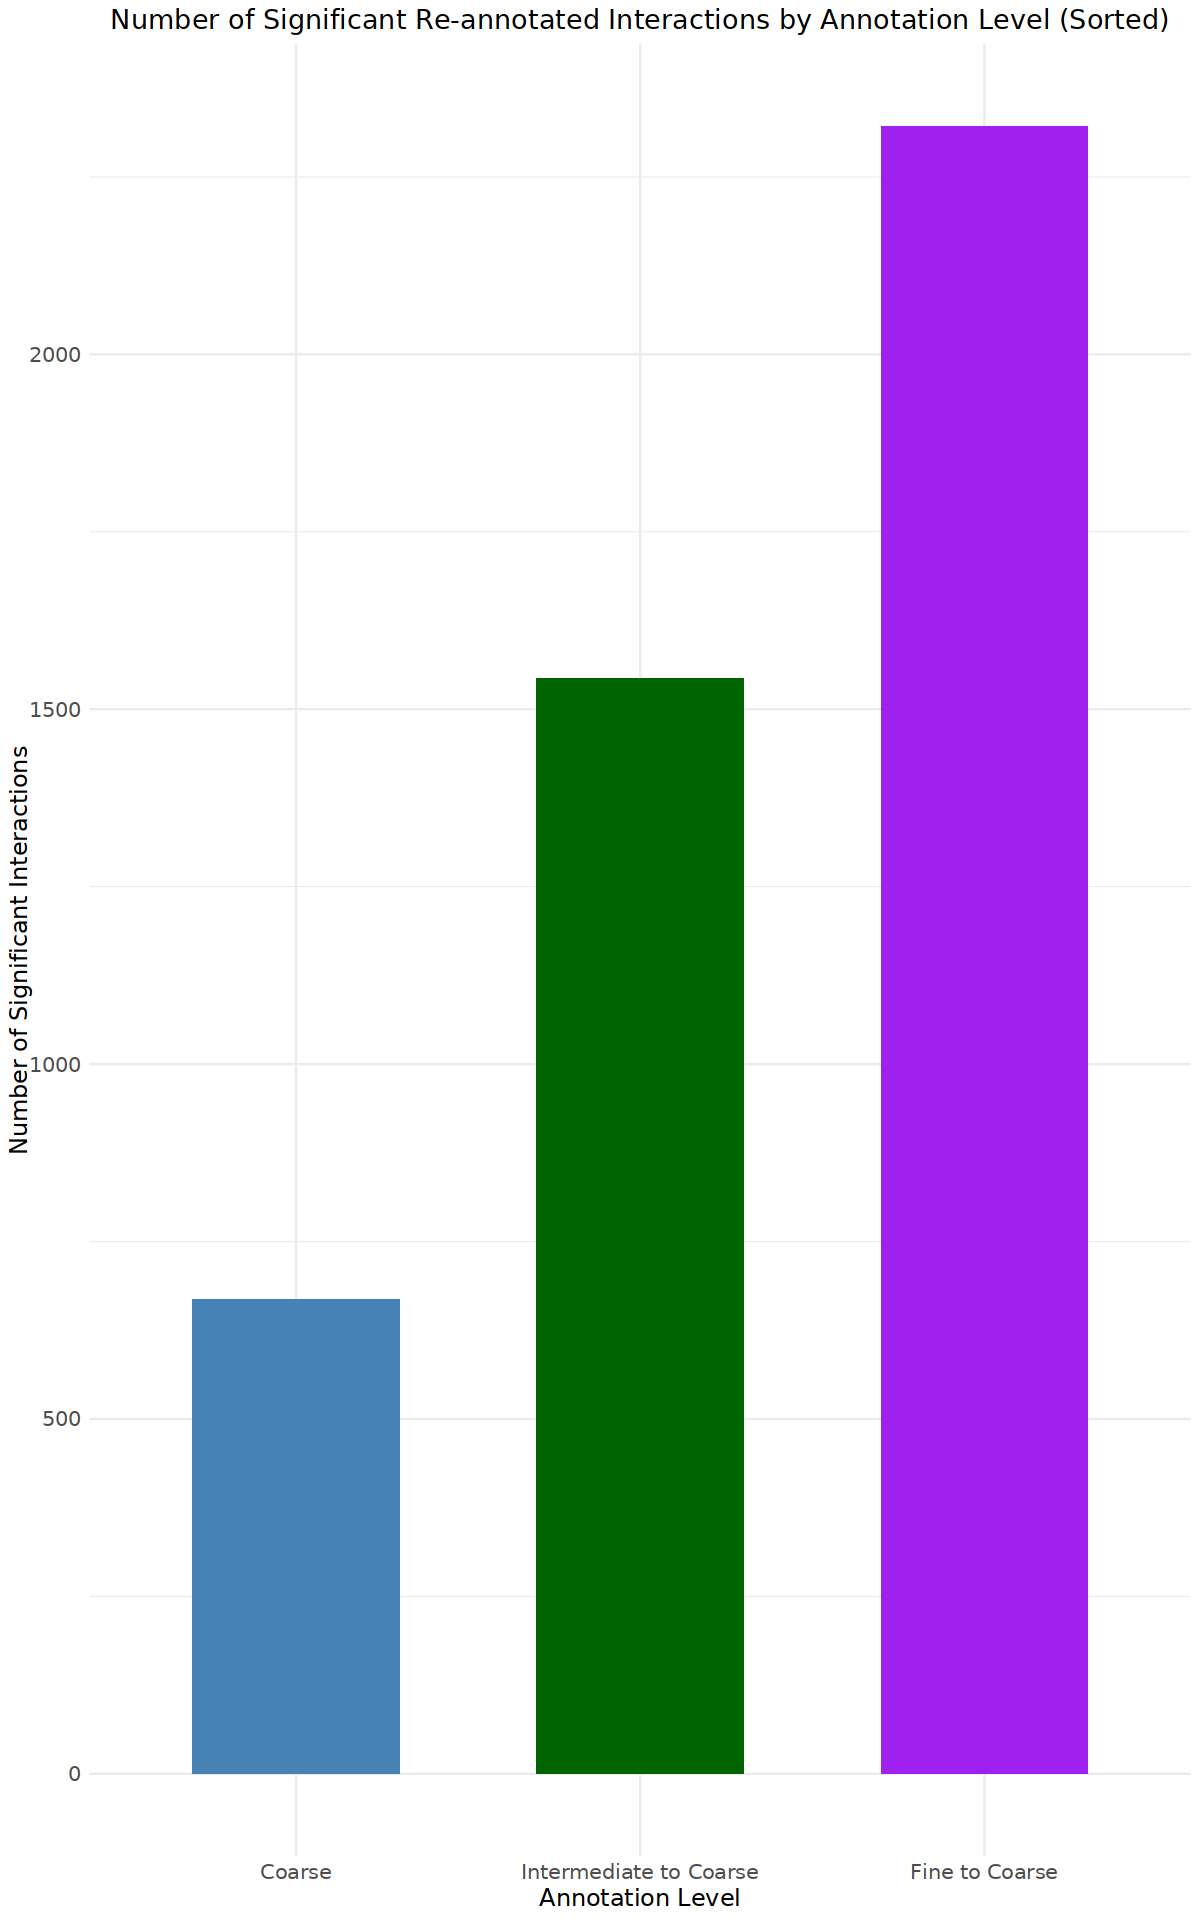

In [7]:
# Number of unique interactions for each annotation level
interaction_counts_unique <- data.frame(
  Annotation_Level = c("Fine to Coarse", "Intermediate to Coarse", "Coarse"),
  Significant_Interactions = c(
    nrow(distinct_broad_unique),
    nrow(general_broad_unique),
    nrow(broad_interactions_unique)
  )
)

# Reorder Annotation_Level based on Significant_Interactions and create the bar plot
interaction_counts_sorted_unique <- interaction_counts_unique %>%
  arrange(Significant_Interactions) %>%
  mutate(Annotation_Level = factor(Annotation_Level, levels = Annotation_Level))

ggplot(interaction_counts_sorted_unique, aes(x = Annotation_Level, y = Significant_Interactions, fill = Annotation_Level)) +
  geom_bar(stat = "identity", width = 0.6) +
  labs(
    title = "Number of Significant Re-annotated Interactions by Annotation Level (Sorted)",
    x = "Annotation Level",
    y = "Number of Significant Interactions"
  ) +
  theme_minimal() +
  theme(
    legend.position = "none",
    plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
    axis.title = element_text(size = 14),
    axis.text = element_text(size = 12)
  ) +
  scale_fill_manual(values = c("Fine to Coarse" = "purple", "Intermediate to Coarse" = "darkgreen", "Coarse" = "steelblue"))

## Sup. Fig. 6f - Overlap of Re-Annotated Interactions

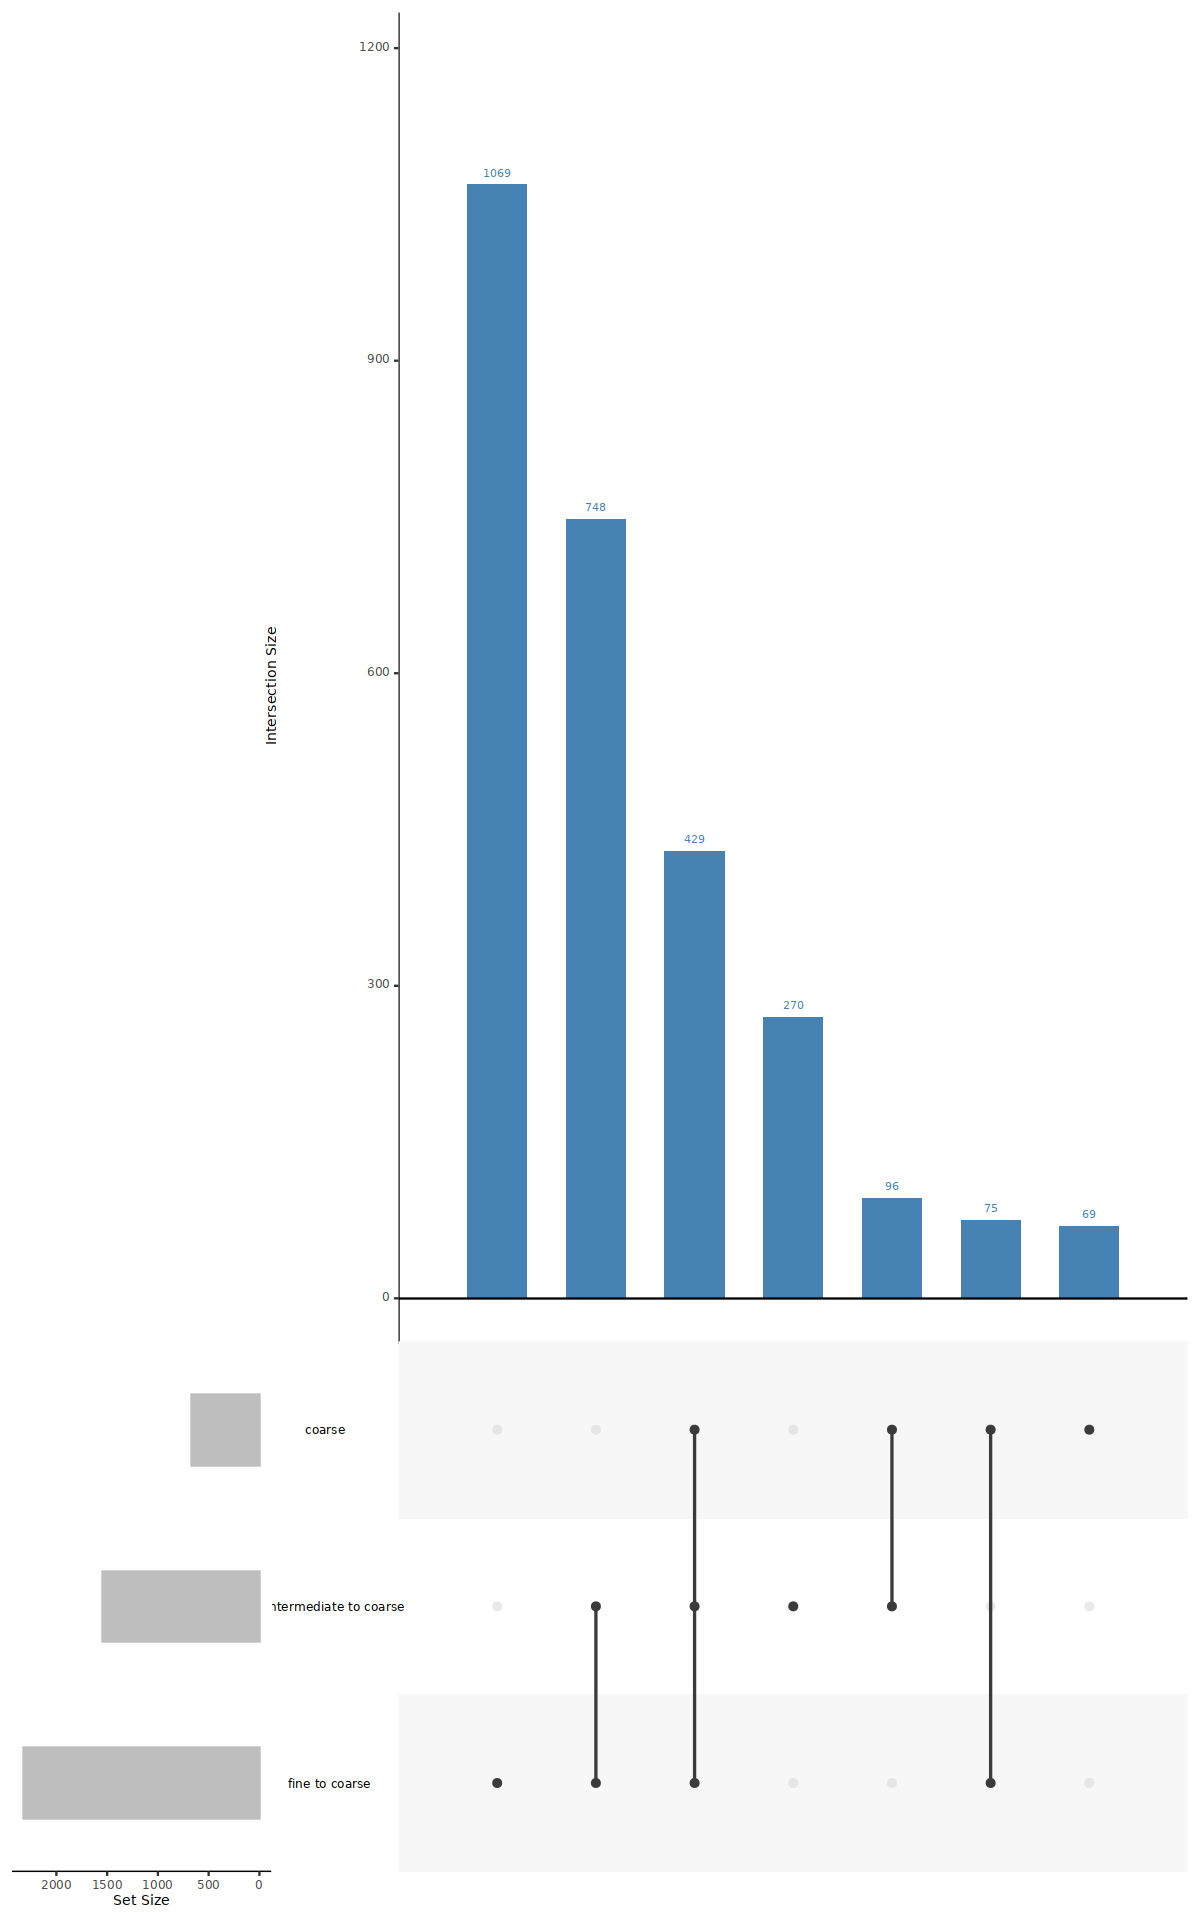

In [8]:
# Prepare interaction IDs for the upset plot
interaction_ids <- function(data) {
  data %>%
    mutate(interaction_id = paste(sending_cell_type, ligand_gene_name, receiving_cell_type, receptor_gene_name, sep = "_")) %>%
    pull(interaction_id)
}

interaction_lists <- list(
  "fine to coarse" = interaction_ids(distinct_broad_unique),
  "intermediate to coarse" = interaction_ids(general_broad_unique),
  "coarse" = interaction_ids(broad_interactions_unique)
)

upset(fromList(interaction_lists), 
      nsets = 3, 
      nintersects = NA, 
      order.by = "freq",
      main.bar.color = "steelblue",
      sets.bar.color = "gray",
      text.scale = 1,
      mainbar.y.label = "Intersection Size",
      sets.x.label = "Set Size")